<a href="https://colab.research.google.com/github/krishna25045678/Cleaning_home/blob/main/ProblemSet_week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning and Neural Networks

## Tutorial 2: Classification

Welcome to the second tutorial for Machine Learning and Neural Networks. In this session, we will explore how to implement a simple classifier using Python.

However, first we will introduce some useful tools and libraries that we will use throughout this course.


## Useful Python Libraries

### Numpy

NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays. You can easily define arrays of numbers and perform operations on them. For example:

In [1]:
# Basics of arrays:

import numpy as np

a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print(np.concatenate((a, b)))
print(np.concatenate((a, b), axis=0))
print(a+b)
print(a*b)

[1 2 3 4 5 6]
[1 2 3 4 5 6]
[5 7 9]
[ 4 10 18]


Numpy is deisgned to work best when operations on arrays are vectorised. This means that you should avoid using loops to iterate over the elements of an array and instead use the built-in functions that operate on the entire array at once. This is because the operations are implemented in C and are much faster than the equivalent Python code.

In [2]:
# demonstration of vectorization

# generate random data
a = np.random.random(10000).reshape(100, 100)
b = np.random.random(10000).reshape(100, 100)

print(a + b)

# vectorized operations are much faster than loops
from timeit import timeit

print(timeit("a + b", setup="import numpy as np; a = np.random.random(10000).reshape(100, 100); b = np.random.random(10000).reshape(100, 100)"))
print(timeit("[x + y for x, y in zip(a, b)]", setup="import numpy as np; a = np.random.random(10000).reshape(100, 100); b = np.random.random(10000).reshape(100, 100)"))




[[0.4907397  1.40174414 0.2752232  ... 0.90681472 1.29497879 0.91600355]
 [0.71905789 1.11040431 0.81296037 ... 1.06277424 0.64448906 1.36616712]
 [0.43433489 0.5370647  0.67443023 ... 1.08628327 1.19293843 0.67475806]
 ...
 [1.55288058 0.73730322 0.64316253 ... 0.94318129 1.21363121 1.3479539 ]
 [1.46970522 1.32831517 0.78401583 ... 0.95782547 1.84624331 1.66035094]
 [1.20382797 0.92324282 0.82370966 ... 1.18753738 0.52523187 1.23123092]]
14.746542366999961
132.92224678899993


In this case, the time difference is about a factor of 30!

### Pandas

Pandas is a powerful, flexible and easy to use open-source data analysis and data manipulation library built on top of Numpy. It is used for data manipulation, data analysis, and data visualization. The two main data structures in Pandas are Series and DataFrame.

In [3]:
import pandas as pd

a = np.random.random(2000)
b = np.random.random(2000)

df = pd.DataFrame({"a": a, "b": b})
df.head()

,a,b
0,0.663910,0.723787
1,0.814360,0.083168
2,0.479464,0.653149
3,0.857909,0.051587
4,0.708199,0.523111


### Matplotlib

Matplotlib is a widely used library for creating static, animated, and interactive visualizations in Python. It is used for creating static, animated, and interactive visualizations in Python.

### Scipy

SciPy is a scientific computation library that builds on NumPy. It provides more utility functions for optimization, stats, signal processing, and other scientific computing.

## Machine Learning Libraries

In addition to the general-purpose libraries mentioned above, there are several libraries specifically designed for machine learning. We will discuss some of the most popular ones below.

### Scikit-learn

Scikit-learn (often referred to as 'sk-learn') is a free machine learning library for Python. It features various algorithms like support vector machine, random forests, and k-nearest neighbours, and it also supports Python numerical and scientific libraries like NumPy and SciPy. It is intended to provide simple and efficient tools for data mining and data analysis, rather than to provide a research tool.

Scikit-learn implements a wide range of machine learning algorithms, making it easy to test and apply different models to your data. It also provides tools for data preprocessing, model evaluation, and model selection.

#### Data Preprocessing with Scikit-learn

Scikit-learn provides a number of tools for data preprocessing, including:

- Standardization: StandardScaler
- Normalization: MinMaxScaler
- Encoding categorical variables: LabelEncoder, OneHotEncoder
- Imputation of missing values: SimpleImputer
- Feature selection: SelectKBest, RFE
- Dimensionality reduction: PCA, LDA

These tools can help you prepare your data for machine learning algorithms, which often require data to be in a specific format. Some examples of data preprocessing include:



In [5]:
# Examples of data preprocessing with scikit-learn

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

print(a.min(), a.max())
scaler.fit(a.reshape(-1, 1))
a_new = scaler.transform(a.reshape(-1, 1))

print(a_new.min(), a_new.max())

0.00043294299235718814 0.9992415192895516
0.0 0.9999999999999999


scikit-learn also makes it easy to perform key tasks like splitting data into training and test sets:

In [4]:
X_all = np.concatenate((a.reshape(-1, 1), b.reshape(-1, 1)), axis=1)
# now make some y data with some noise

y_all = X_all[:, 0] + 2 * X_all[:, 1] + np.random.normal(0, 0.1, 2000)

print(X_all.shape, y_all.shape)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(2000, 2) (2000,)
(1600, 2) (400, 2) (1600,) (400,)


#### Model training and evaluation with Scikit-learn

Scikit-learn provides a wide range of machine learning algorithms, including:

- Classification: Logistic Regression, Decision Trees, Random Forests, Support Vector Machines, k-Nearest Neighbors
- Regression: Linear Regression, Ridge Regression, Lasso Regression, Support Vector Regression
- Clustering: K-Means, DBSCAN, Hierarchical Clustering
- Dimensionality reduction: PCA, LDA, t-SNE
- Density estimation: Gaussian Mixture Models, Kernel Density Estimation
- Model evaluation: Cross-validation, Grid Search, Model selection

These algorithms are ready to use out of the box, making it easy to experiment with different models and find the best one for your data.

For example, if we want to perform linear regression on the data we can do the following:


In [6]:
# simple linear regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(model.score(X_test, y_test))

0.9788759044738389


We can also apply it to simple classification problems:

In [ ]:
# make some fake data for classification

X = np.random.random(2000).reshape(1000, 2)
Y = np.random.choice(['cat', 'dog'], 1000)

print(X.shape, Y.shape)

# one-hot encode the Y data
from sklearn.preprocessing import OneHotEncoder
y_ohe = OneHotEncoder().fit_transform(Y.reshape(-1, 1)).toarray()
print(y_ohe.shape)

# split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_ohe, test_size=0.2)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# now use a k-nearest neighbors model to classify the data
# this won't be very good because the data is completely random

from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(model.score(X_test, y_test))

The result of the classifier is not very good. Why is the score almost exactly 0.5?

If we want to then do cross-validation to evaluate the model, we can do the following:

In [7]:
# take our already generated data and perform cross-validation to find the optimal number of neighbours

from sklearn.model_selection import GridSearchCV

n_neighbors = [5, 10, 15, 20, 25, 30]

model = KNeighborsClassifier()

parameters = {'n_neighbors': n_neighbors}

clf = GridSearchCV(model, parameters, cv=5)

clf.fit(X, y_ohe)

print(clf.best_params_)

NameError: name 'KNeighborsClassifier' is not defined

This has automatically split the data into 5 folds, trained the model on 4 of them, and evaluated it on the remaining fold. It then repeats this process 5 times, using a different fold as the test set each time, and then repeats this for each value of the number of neighbours that we want to test. It automatically selects the best value of k based on the cross-validation results.

You can also implement a simple neural network using scikit-learn (useful later on in the course). However, for more complex neural networks, you may want to use a dedicated library like TensorFlow or PyTorch. Nevertheless, scikit-learn can let you get simple neural networks up and running quickly.

In [8]:
from sklearn.neural_network import MLPRegressor

model = MLPRegressor(hidden_layer_sizes=(100, 100), max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(model.score(X_test, y_test))

0.9780843432880862


Throughout the ML part of this course, we will use scikit-learn to implement and evaluate machine learning models. For the Neural Networks part of the course, we will start using scikit-learn to implement simple neural networks, and then move on to using specialised libraries for tensor and neural-network computations (such as TensorFlow and PyTorch) for more complex models.

### TensorFlow

TensorFlow is an open-source machine learning library developed by Google. It is used for implementing and training deep learning models. TensorFlow provides a comprehensive ecosystem of tools for building and deploying machine learning models.

TensorFlow is widely used in the industry for various applications like image recognition, natural language processing, and more.

In [9]:
# define a simple network with two hidden layers using only tensorflow

import tensorflow as tf

# To define a model you need to create a class
class BetterModelHidden(tf.Module):
  def __init__(self, **kwargs):
    super().__init__(**kwargs)
    self.w0 = tf.Variable(tf.random.uniform([2, 20]))
    self.b0 = tf.Variable(0.0)

    self.w1 = tf.Variable(tf.random.uniform([20, 2]))
    self.b1 = tf.Variable(0.0)

  def __call__(self, x0):
    x1 = tf.nn.sigmoid(x0 @ self.w0 + self.b0)
    return tf.nn.softmax(x1 @ self.w1 + self.b1)

# then instantiate it
model = BetterModelHidden()

# and training it is much more complicated:
for i_epochs in range(50):
    with tf.GradientTape() as tape:
        y_pred = model(X_train)
        loss = tf.reduce_mean(-tf.reduce_sum(y_train * tf.math.log(y_pred), axis=1))
    gradients = tape.gradient(loss, model.variables)
    optimizer = tf.optimizers.Adam(learning_rate=0.1)
    optimizer.apply_gradients(zip(gradients, model.variables))

InvalidArgumentError: {{function_node __wrapped__Mul_device_/job:localhost/replica:0/task:0/device:CPU:0}} Incompatible shapes: [1600] vs. [1600,2] [Op:Mul] name: 

### Keras

Keras is an open-source deep learning library written in Python. It is designed to be user-friendly, modular, and extensible. Keras can run on top of other libraries to provide a high-level interface for building and training deep learning models. It is particularly designed for tight integration with TensorFlow. It particularly makes some of the steps involved in training a neural network easier, such as choosing the optimiser and performing the training loop.

In [ ]:
import tensorflow as tf

# derefining the same model using tensorflow's built-in keras integration
model = tf.keras.models.Sequential([
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(2)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error')

history = model.fit(X_train, y_train, epochs=100, validation_split=0.2)

### PyTorch

PyTorch is an open-source machine learning library developed by Facebook. It is used for implementing and training deep learning models. PyTorch provides a flexible and dynamic computational graph, which makes it easier to work with dynamic neural networks.

PyTorch is particularly popular in the research community for its flexibility and ease of use. A large ecosystem of tools and libraries has been built around PyTorch to support various machine learning tasks. It adopts an object-oriented approach to building neural networks, which makes it easy to experiment with different architectures and training algorithms.

In [10]:
import torch

torch.manual_seed(0)

class Net(torch.nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = torch.nn.Linear(2, 100)
        self.fc2 = torch.nn.Linear(100, 100)
        self.fc3 = torch.nn.Linear(100, 2)

    def forward(self, x):
        x = torch.nn.functional.relu(self.fc1(x))
        x = torch.nn.functional.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = Net()

# similar to tensorflow, we need to choose an optimizer and a loss
loss = torch.nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

# but we don't need to compile the model
# we can just train it
# notice how torch forces us to write out all the details of training - this is why it is popular in research
n_epochs = 100
for epoch in range(n_epochs):
    y_pred = model(torch.as_tensor(X_train).float())
    loss_value = loss(torch.as_tensor(y_pred), torch.as_tensor(y_train).float())
    optimizer.zero_grad()
    loss_value.backward()
    optimizer.step()



/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([1600])) that is different to the input size (torch.Size([1600, 2])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


RuntimeError: The size of tensor a (2) must match the size of tensor b (1600) at non-singleton dimension 1

Torch gives you maximum control over your model and training process, which can be useful for research and experimentation. However, it can also be more complex to use than keras, which is designed to be more user-friendly and production-ready. However, you can use keras with pytorch, or other frameworks such as PyTorch Lightning, which provide a higher-level interface for building and training models.

This model we defined above now has some key attributes that you can track, for example:

In [ ]:
for p in model.parameters():
    print(p)

Torch also provides some key tools that you may need in later courses, such as DataLoader, which can be used to load data in a controlled way for training neural networks. This is particularly useful when working with large datasets that do not fit into memory.

Another  key aspect of PyTorch is its `Tensor` objects, which are similar to NumPy arrays but can be used on GPUs and for which automatic differentiation is available. This allows you to perform computations on GPUs easily.

In [ ]:
t = torch.tensor(X_test, dtype=torch.float32)
t.grad

### JAX

Technically, JAX is not a machine learning library, but rather a numerical computing library. It provides high-performance numerical computing (e.g. automatic GPU computing) and automatic differentiation in Python, making it a replacement for `numpy` with the addition of automatic differentiation. Unlike PyTorch, JAX adopts a functional programming paradigm, and JAX is designed to be composable, which means you can combine different functions and transformations to build complex numerical programs. As a result, it is particularly well-suited for building custom machine learning models and algorithms using frameworks built on top of JAX. These adopt a range of approaches; the one most similar to PyTorch is `equinox`, which provides a similar object-oriented interface to PyTorch.

In [11]:
import jax
from jax import numpy as jnp
%pip install equinox
import equinox as eqx

jax_array = jax.random.normal(jax.random.PRNGKey(0), (1000, 2))

print(jax_array.shape)

# define a simple network with two hidden layers using only jax

class Net(eqx.Module):

    def __init__(self):
        self.fc1 = eqx.nn.Linear(2, 100)
        self.fc2 = eqx.nn.Linear(100, 100)
        self.fc3 = eqx.nn.Linear(100, 2)

    def __call__(self, x):
        x = jnp.tanh(self.fc1(x))
        x = jnp.tanh(self.fc2(x))
        x = self.fc3(x)
        return x

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.4 MB/s eta 0:00:00
(1000, 2)


### Useful tricks: ipython magic commands

In Jupyter notebooks, you can use special commands called "magic commands" to perform various tasks. For example, you can use the `%timeit` magic command to measure the time taken by a code snippet to run. You can also use the `%matplotlib inline` magic command to display plots inline in the notebook.

In [ ]:
%timeit model(jax_array)

A particularly useful magic command is `%pip install`, which allows you to install packages directly from the notebook. For example, you can use `%pip install numpy` to install the NumPy library. This can be useful if you need to install a package that is not already installed on your system and want to ensure it is installed within a virtual environment. The alternative is to install the package by calling `!pip install numpy` which tells juptyer to run the command in the shell - this can result in the package being installed in the wrong environment!

You can combine this particular aspect of ipython magic to create simple logic that checks if a package is installed and installs it if it is not. For example:

In [ ]:
try:
    import sklearn
except (ModuleNotFoundError, ImportError) as e:
    %pip install scikit-learn

This will only install the package if it isn't already installed. This can be useful if you are sharing code with others and want to ensure that they have all the necessary packages installed. Try making a more complex version that checks the version of the package and only installs it if it is below a certain version or not present.

In [ ]:
# check for a specific version of scikit-learn here:

## Classification with Scikit-learn



Scikit-learn is very popular for it's wide variety of easy-to-use classifiers. We will now introduce a few problems for you to solve using scikit-learn.

### Problem 1:

Read the dataset in the file `dataset_1.csv` and split it into a training set and a test set. Train a logistic regression classifier on the training set and evaluate it on the test set. What is the accuracy of the classifier?

In [13]:
# Put your solution here:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from google.colab import files

# This will prompt you to select and upload 'dataset_1.csv' from your computer
uploaded = files.upload()

# 1. Load the dataset
df = pd.read_csv('dataset_1.csv')

# Note: Assuming the last column is the target/label and all previous columns are features.
# If your target column has a specific name (e.g., 'target'), you can use:
# X = df.drop(columns=['target'])
# y = df['target']
X = df.iloc[:, :-1]  # Features
y = df.iloc[:, -1]   # Target variable

# 2. Split the dataset into a training set (80%) and a test set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Logistic Regression classifier
classifier = LogisticRegression(max_iter=1000)
classifier.fit(X_train, y_train)

# 4. Predict and evaluate on the test set
y_pred = classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy of the Logistic Regression classifier: {accuracy:.4f}")



Saving dataset_1.csv to dataset_1.csv
Accuracy of the Logistic Regression classifier: 0.9150


#### Problem 2:

Read the dataset in the file `dataset_2.csv` and split it into a training set and a test set. Train a k-nearest neighbours classifier on the training set and evaluate it on the test set. What is the accuracy of the classifier? This dataset is not as clean as the previous one, so you may need to do some data preprocessing before training the classifier.

Now find the best value of k for the k-nearest neighbours classifier using the elbow method. What is the best value of k?

Saving dataset_2.csv to dataset_2.csv
Baseline Accuracy (k=5): 0.7700



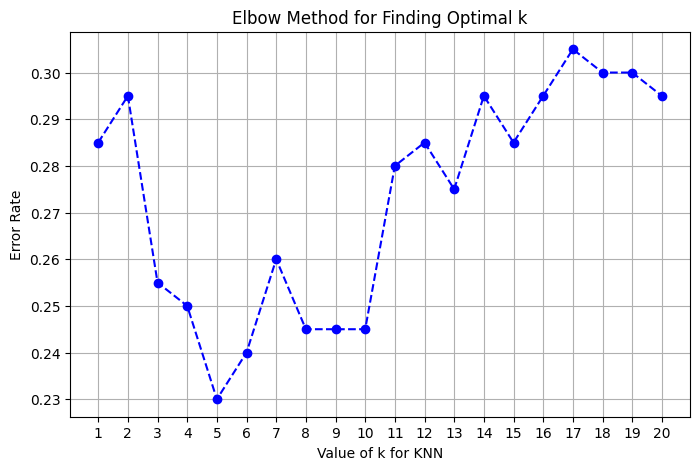

The best value of k is: 5


In [15]:
# Put your solution here:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from google.colab import files

# Upload 'dataset_2.csv' from your local computer
uploaded = files.upload()

# 1. Load the dataset
df = pd.read_csv('dataset_2.csv')

# Assuming the last column is the target/label and all previous columns are features
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# 2. Identify numerical and categorical columns for preprocessing
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Create preprocessing pipelines for both numeric and categorical data
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Fill missing numeric values with median
    ('scaler', StandardScaler())                 # Scale features (Critical for KNN!)
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Fill missing categorical values
    ('onehot', OneHotEncoder(handle_unknown='ignore'))      # Convert text to binary columns
])

# Combine preprocessing steps into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 3. Split the dataset into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train a baseline KNN classifier (e.g., k=5) and evaluate
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)
y_pred = knn_pipeline.predict(X_test)
print(f"Baseline Accuracy (k=5): {accuracy_score(y_test, y_pred):.4f}\n")

# 5. Find the best value of k using the Elbow Method (Error Rate vs. k)
error_rates = []
k_range = range(1, 21)

for k in k_range:
    # Update pipeline with current k
    knn_pipeline.set_params(classifier__n_neighbors=k)
    knn_pipeline.fit(X_train, y_train)

    # Predict on test set and calculate error rate (1 - accuracy)
    preds = knn_pipeline.predict(X_test)
    error_rate = 1 - accuracy_score(y_test, preds)
    error_rates.append(error_rate)

# Plot the Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(k_range, error_rates, marker='o', linestyle='--', color='b')
plt.title('Elbow Method for Finding Optimal k')
plt.xlabel('Value of k for KNN')
plt.ylabel('Error Rate')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Find the best k (the one with the lowest error rate)
best_k = k_range[np.argmin(error_rates)]
print(f"The best value of k is: {best_k}")


#### Problem 3:

Read the dataset in the file `dataset_3.csv` and split it into a training set and a test set. Find the best values of the hyperparameters C and gamma for a support vector machine classifier using grid search. What are the best values of the hyperparameters?

In [17]:
# Enter your solution here:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from google.colab import files

# Upload 'dataset_3.csv' from your local machine
uploaded = files.upload()

# 1. Load the dataset
# Note: Ensure dataset_3.csv is in your working directory (or use the full file path if needed)
df = pd.read_csv('dataset_3.csv')

# Assuming the last column is the target/label and all previous columns are features
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# 2. Split the dataset into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Create a Pipeline with Feature Scaling and SVM Classifier
# Feature scaling is mandatory for SVMs because they rely on distance metrics/margins.
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf')) # RBF kernel is typically used for non-linear decision boundaries
])

# 4. Define the hyperparameter grid for C and gamma to search through
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

# 5. Set up GridSearchCV using 5-fold cross-validation on the training set
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,               # 5-fold cross-validation
    scoring='accuracy', # Metric to optimize
    n_jobs=-1           # Use all available CPU cores for faster computation
)

# 6. Fit Grid Search to the training data
grid_search.fit(X_train, y_train)

# 7. Output the best hyperparameters found
print("--- Grid Search Results ---")
print(f"Best C: {grid_search.best_params_['svc__C']}")
print(f"Best gamma: {grid_search.best_params_['svc__gamma']}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

# 8. Evaluate the best model on the test set
test_accuracy = grid_search.score(X_test, y_test)
print(f"Test Set Accuracy: {test_accuracy:.4f}")





Saving dataset_3.csv to dataset_3.csv
--- Grid Search Results ---
Best C: 1
Best gamma: 0.1
Best Cross-Validation Accuracy: 0.8012
Test Set Accuracy: 0.8200


For an extension, try to also find the best kernel for the support vector machine classifier. What is the best kernel?

In [18]:
# Enter your solution here:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 1. Load the dataset (Ensure dataset_3.csv is in your working directory or uploaded)
df = pd.read_csv('dataset_3.csv')

# Assuming the last column is the target/label and all previous columns are features
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# 2. Split the dataset into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Create a Pipeline with Feature Scaling and SVM Classifier
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

# 4. Define a list of parameter dictionaries to search across multiple kernels
param_grid = [
    # Linear kernel grid
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.1, 1, 10, 100]
    },
    # RBF kernel grid
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
    },
    # Polynomial kernel grid
    {
        'svc__kernel': ['poly'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__degree': [2, 3],
        'svc__gamma': ['scale', 'auto']
    },
    # Sigmoid kernel grid
    {
        'svc__kernel': ['sigmoid'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto']
    }
]

# 5. Set up GridSearchCV using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,               # 5-fold cross-validation
    scoring='accuracy', # Metric to optimize
    n_jobs=-1           # Use all available CPU cores
)

# 6. Fit Grid Search to the training data
grid_search.fit(X_train, y_train)

# 7. Output the best hyperparameters (including the best kernel)
print("--- Extended Grid Search Results ---")
print(f"Best Kernel: {grid_search.best_params_['svc__kernel']}")
print(f"Best C: {grid_search.best_params_['svc__C']}")

# Print gamma or degree only if they exist in the best parameters for that specific kernel
if 'svc__gamma' in grid_search.best_params_:
    print(f"Best gamma: {grid_search.best_params_['svc__gamma']}")
if 'svc__degree' in grid_search.best_params_:
    print(f"Best degree: {grid_search.best_params_['svc__degree']}")

print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

# 8. Evaluate the winning model on the test set
test_accuracy = grid_search.score(X_test, y_test)
print(f"Test Set Accuracy: {test_accuracy:.4f}")

--- Extended Grid Search Results ---
Best Kernel: rbf
Best C: 1
Best gamma: 0.1
Best Cross-Validation Accuracy: 0.8012
Test Set Accuracy: 0.8200


#### Problem 4:

Read the dataset in the file `dataset_4.csv`. Identify which classifier is best suited for this dataset. What is the accuracy of the best classifier?


In [20]:
# Enter your solution here:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Classifiers to benchmark
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import os
from google.colab import files  # Remove this line if you are NOT using Google Colab

# 1. Check what files are currently in your directory
print("Current files in directory:", os.listdir())

# 2. If 'dataset_4.csv' is not in the list above, upload it interactively:
if 'dataset_4.csv' not in os.listdir():
    print("\n'dataset_4.csv' not found. Please upload it using the prompt below:")
    uploaded = files.upload()

# 3. Now load the dataset safely
df = pd.read_csv('dataset_4.csv')
print("Dataset loaded successfully! Shape:", df.shape)

# 1. Load the dataset
# (Make sure dataset_4.csv is in your working directory or uploaded if using Colab)
df = pd.read_csv('dataset_4.csv')

# Assuming the last column is the target/label and all previous columns are features
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# 2. Identify numerical and categorical features for robust cleaning
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# 3. Define preprocessing pipelines for missing values and scaling/encoding
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 4. Split the dataset into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Define a dictionary of multiple classifiers to test
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(),
    'Random Forest': RandomForestClassifier(random_state=42)
}

best_score = 0
best_name = ""

print("--- Benchmarking Classifiers ---")
for name, clf in classifiers.items():
    # Combine preprocessing and model into a single pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

    # Train the classifier
    pipeline.fit(X_train, y_train)

    # Predict and evaluate accuracy on the test set
    y_pred = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"{name} -> Accuracy: {accuracy:.4f}")

    # Track the best performing model
    if accuracy > best_score:
        best_score = accuracy
        best_name = name

print("\n========================================")
print(f"Best Suited Classifier: {best_name}")
print(f"Accuracy of the Best Classifier: {best_score:.4f}")
print("========================================")


Current files in directory: ['.config', 'dataset_3.csv', 'dataset_2.csv', 'dataset_1.csv', 'sample_data']

'dataset_4.csv' not found. Please upload it using the prompt below:


Saving dataset_4.csv to dataset_4.csv
Dataset loaded successfully! Shape: (1000, 18)
--- Benchmarking Classifiers ---
Logistic Regression -> Accuracy: 0.7000
K-Nearest Neighbors -> Accuracy: 0.8200
Support Vector Machine -> Accuracy: 0.8650
Random Forest -> Accuracy: 0.8100

Best Suited Classifier: Support Vector Machine
Accuracy of the Best Classifier: 0.8650
